# Tiền xử lý Tiki — bảng 21 cột đã chốt




## 1. Đọc và ghép dữ liệu
### 1.1. Thư viện

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import IsolationForest

plt.rcParams.update({"figure.dpi": 120, "font.size": 10})


### 1.2. Đường dẫn và tham số

In [ ]:
input_folder = Path("Dữ liệu raw")
product_file = input_folder / "tiki_products_raw.csv"
seller_file = input_folder / "tiki_sellers_raw.csv"
output_folder = Path(".")
output_folder.mkdir(parents=True, exist_ok=True)
excel_file = output_folder / "tiki_du_lieu_nghien_cuu.xlsx"

### 1.3. Đọc dữ liệu nguồn

In [ ]:
df_p = pd.read_csv(product_file)
seller_columns = [
    "seller_id", "s_avg_rating_point", "s_review_count",
    "s_total_follower", "s_is_official",
]
df_s = pd.read_csv(
    seller_file, usecols=seller_columns + ["seller_name", "s_days_since_joined"]
)
print("Sản phẩm:", df_p.shape)
print("Nhà bán — các cột cần dùng:", df_s.shape)


Sản phẩm: (3162, 29)
Nhà bán — các cột cần dùng: (395, 7)


### 1.4. Ghép bảng sản phẩm và nhà bán

In [ ]:
df = df_p.merge(df_s[seller_columns], on="seller_id", how="left", validate="many_to_one")
if len(df) != len(df_p):
    raise ValueError("Số dòng sau ghép không bằng số sản phẩm nguồn.")
before = df.copy()
print("Dữ liệu sau ghép:", df.shape)


Dữ liệu sau ghép: (3162, 33)


## 2. Kiểm tra dữ liệu gốc
### 2.1. Chất lượng dữ liệu và trùng lặp

In [ ]:
quality_before = pd.DataFrame({
    "Count": df.count(),
    "Unique": df.nunique(),
    "Null": df.isna().sum(),
    "Null_pct": df.isna().mean() * 100,
    "DType": df.dtypes.astype(str),
})
display(quality_before)
print("Trùng toàn dòng:", df.duplicated().sum())

,Count,Unique,Null,Null_pct,DType
product_id,3162,3162,0,0.000000,int64
name,3162,3148,0,0.000000,object
price,3162,1374,0,0.000000,int64
list_price,3162,1099,0,0.000000,int64
discount_rate,3162,68,0,0.000000,int64
rating_average,3162,24,0,0.000000,float64
review_count,3162,335,0,0.000000,int64
quantity_sold,2041,741,1121,35.452245,float64
brand_name,2874,527,288,9.108159,object
seller_id,3162,395,0,0.000000,int64


Trùng toàn dòng: 0


### 2.2. Điều tra Y thiếu theo review, nguồn mẫu và tuổi

In [ ]:
missing_y = df["quantity_sold"].isna()
for group in ["listing_sort", "listing_category"]:
    print("Tỷ lệ Y thiếu theo", group)
    display(missing_y.groupby(df[group]).agg(n="size", missing="sum", rate="mean"))

print("Tỷ lệ Y thiếu theo trạng thái có review sản phẩm")
display(missing_y.groupby(df["review_count"].gt(0)).agg(
    n="size", missing="sum", rate="mean",
))


print("Tuổi sản phẩm theo tình trạng thiếu Y — đơn vị ngày")
display(df["day_ago_created"].groupby(missing_y).agg(["count", "median"]))

missing_with_review = missing_y & df["review_count"].gt(0)
print("Thiếu Y nhưng có review:", int(missing_with_review.sum()))
print("Không review nhưng có Y dương:", int(
    (df["review_count"].eq(0) & df["quantity_sold"].gt(0)).sum()
))
print("Ví dụ dòng thiếu Y nhưng có review:")
display(df.loc[missing_with_review, [
    "product_id", "seller_id", "name", "quantity_sold", "review_count",
]].head(10))


Tỷ lệ Y thiếu theo listing_sort


,n,missing,rate
listing_sort,,,
newest,1014,949,0.935897
top_seller,2148,172,0.080074


Tỷ lệ Y thiếu theo listing_category


,n,missing,rate
listing_category,,,
Dien gia dung,320,118,0.368750
Dien thoai - May tinh bang,111,69,0.621622
Do choi - Me & be,240,79,0.329167
Lam dep - Suc khoe,310,144,0.464516
Laptop - May vi tinh,517,124,0.239845
Nha cua - Doi song,318,122,0.383648
Nha sach Tiki,317,108,0.340694
O to - Xe may - Xe dap,280,95,0.339286
The thao - Da ngoai,320,128,0.400000


Tỷ lệ Y thiếu theo trạng thái có review sản phẩm


,n,missing,rate
review_count,,,
False,1453,1079,0.742602
True,1709,42,0.024576


Tuổi sản phẩm theo tình trạng thiếu Y — đơn vị ngày


,count,median
quantity_sold,,
False,2041,1041.0
True,1121,26.0


Thiếu Y nhưng có review: 42
Không review nhưng có Y dương: 374
Ví dụ dòng thiếu Y nhưng có review:


,product_id,seller_id,name,quantity_sold,review_count
486,279254865,29952,Điện Thoại Xiaomi Redmi Note 15 Pro 5G 12GB/25...,NaN,1
507,279076844,29952,Điện Thoại Xiaomi Redmi Note 15 5G 6GB/128GB -...,NaN,1
951,279307222,364764,Thẻ nhớ 8GB 16GB 32GB 64GB 128GB 256GB 512GB t...,NaN,7
1030,279171403,173338,Thẻ nhớ MicroSD Hoco 8GB/16GB/32GB/64GB/128GB ...,NaN,1
1032,278731885,159903,Bao Case Ốp Silicone Color cho Airpods Pro 3 (...,NaN,2
1034,278136187,148809,Kính Cường Lực kèm khung trợ dán Dux Ducis Rog...,NaN,1
1035,277811636,181601,"Bao da vải Mutural dành cho ipad A16 Gen 11 , ...",NaN,1
1071,278674325,184829,"Bao Da Dạng Ví Dành Cho iPhone Air, iPhone 17,...",NaN,1
1118,276887053,1710,Dây cáp sạc nhanh 2.4A USB-A to Type C Hiệu WI...,NaN,1
1149,278955361,257872,Bao da Máy tính bảng Samsung Galaxy Tab A11 Pl...,NaN,1


### 2.3. Đối chiếu nhãn ngành

Lấy ngành cấp 1 từ category_path. Bảng này giúp phát hiện nhãn thu thập sai.

In [ ]:
category_check = pd.crosstab(
    df["listing_category"], df["category_path"].str.split(" > ").str[0],
)
display(category_check)


category_path,Laptop - Máy Vi Tính - Linh kiện,Nhà Cửa - Đời Sống,Nhà Sách Tiki,Thiết Bị Số - Phụ Kiện Số,Thể Thao - Dã Ngoại,Thời trang nam,Ô Tô - Xe Máy - Xe Đạp,Điện Gia Dụng,Điện Thoại - Máy Tính Bảng,Đồ Chơi - Mẹ & Bé
listing_category,,,,,,,,,,
Dien gia dung,0,0,0,0,0,0,0,320,0,0
Dien thoai - May tinh bang,0,0,0,0,0,0,0,0,111,0
Do choi - Me & be,0,0,0,0,0,0,0,0,0,240
Lam dep - Suc khoe,0,0,0,0,0,310,0,0,0,0
Laptop - May vi tinh,517,0,0,0,0,0,0,0,0,0
Nha cua - Doi song,0,318,0,0,0,0,0,0,0,0
Nha sach Tiki,0,0,317,0,0,0,0,0,0,0
O to - Xe may - Xe dap,0,0,0,0,0,0,280,0,0,0
The thao - Da ngoai,0,0,0,0,320,0,0,0,0,0


### 2.4. Kiểm tra miền giá trị

In [ ]:
range_checks = pd.Series({
    "Giá không dương": df["price"].le(0).sum(),
    "Giá bán cao hơn niêm yết": df["price"].gt(df["list_price"]).sum(),
    "Số bán âm": df["quantity_sold"].lt(0).sum(),
    "Review âm": df["review_count"].lt(0).sum(),
    "Tuổi sản phẩm âm": df["day_ago_created"].lt(0).sum(),
    "Rating sản phẩm ngoài 0–5": (df["rating_average"].notna() & ~df["rating_average"].between(0, 5)).sum(),
})
display(range_checks)

Giá không dương              0
Giá bán cao hơn niêm yết     0
Số bán âm                    0
Review âm                    0
Tuổi sản phẩm âm             0
Rating sản phẩm ngoài 0–5    0
dtype: int64

In [ ]:
# Độ lệch của lượng bán và trung vị giá theo ngành hàng.
eda_skewness = pd.DataFrame({
    "Biến": ["quantity_sold"],
    "Độ lệch": before[["quantity_sold"]].skew().values
})
display(eda_skewness.round(3))
source_category = (before["category_path"].astype("string").str.split(" > ").str[0].str.strip())
category_median_price = ( before.assign(main_category=source_category).groupby("main_category")["price"].median())

display(
    category_median_price
    .sort_values()
    .rename("Trung vị giá (đồng)")
    .to_frame()
)

,Biến,Độ lệch
0,quantity_sold,9.721


,Trung vị giá (đồng)
main_category,
Nhà Sách Tiki,113300.0
Thiết Bị Số - Phụ Kiện Số,215000.0
Thời trang nam,216280.0
Thể Thao - Dã Ngoại,221450.0
Nhà Cửa - Đời Sống,300800.0
Ô Tô - Xe Máy - Xe Đạp,342231.5
Laptop - Máy Vi Tính - Linh kiện,365000.0
Đồ Chơi - Mẹ & Bé,413000.0
Điện Gia Dụng,959000.0


## 3. Điều tra dữ liệu nhà bán và tạo các biến cần dùng

### 3.1. Loại dòng thiếu Y sau khi điều tra

Loại toàn bộ dòng thiếu `quantity_sold`


In [ ]:
# Loại sản phẩm thiếu Y trước khi kiểm tra nhà bán
n_before = len(df)
n_missing_y = int(df["quantity_sold"].isna().sum())
df = df.loc[df["quantity_sold"].notna()].copy()


df["sold_log"] = np.log1p(df["quantity_sold"])
print("Trước lọc:", n_before)
print("Đã loại dòng thiếu Y:", n_missing_y)
print("Còn lại:", len(df))


Trước lọc: 3162
Đã loại dòng thiếu Y: 1121
Còn lại: 2041


### 3.2. Kiểm tra tính nhất quán và ngoại lai đa biến của nhà bán

#### 3.2.1. Xác định các trường hợp cần điều tra từ dữ liệu


In [ ]:
seller_review_mask = (
    df_s["s_days_since_joined"].eq(0)
    & df_s["s_review_count"].gt(0)
)
seller_review_columns = [
    "seller_id", "seller_name", "s_days_since_joined",
    "s_review_count", "s_total_follower",
]
print("Nhà bán có tuổi 0 nhưng đã có đánh giá:", int(seller_review_mask.sum()))
display(df_s.loc[seller_review_mask, seller_review_columns]
        .sort_values("s_review_count", ascending=False))


Nhà bán có tuổi 0 nhưng đã có đánh giá: 5


,seller_id,seller_name,s_days_since_joined,s_review_count,s_total_follower
169,44857,DAMAS Official Store,0,5215,0
250,131706,Bách Hóa Sữa Bột,0,2512,0
56,112115,TỔNG KHO ĐIỆN MÁY - GIA DỤNG,0,1200,0
63,42132,Noithat Lams,0,544,0
88,73305,Công Nghệ và Truyền Thông Zlink,0,1,0


#### 3.2.2. Đối chiếu bằng Isolation Forest

In [ ]:
features = [
    "s_days_since_joined",
    "s_review_count",   
    "s_total_follower",
]
seller_X = df_s[features]
seller_valid = seller_X.notna().all(axis=1)


seller_model = IsolationForest(
    n_estimators=500, contamination="auto", random_state=42, n_jobs=-1
)
seller_labels = seller_model.fit_predict(seller_X.loc[seller_valid])

seller_audit = df_s[seller_review_columns].copy()
seller_audit["is_outlier"] = pd.Series(pd.NA, index=df_s.index, dtype="boolean")
seller_audit.loc[seller_valid, "is_outlier"] = seller_labels == -1
# Đảo dấu score_samples: điểm càng cao thì càng bất thường.
seller_audit["anomaly_score"] = np.nan
seller_audit.loc[seller_valid, "anomaly_score"] = (
    -seller_model.score_samples(seller_X.loc[seller_valid])
)

seller_review_result = seller_audit.loc[seller_review_mask].sort_values(
    "anomaly_score", ascending=False
)
print(f"Số nhà bán được mô hình đánh giá: {seller_valid.sum()}/{len(df_s)}")
display(seller_review_result)
print("Trong nhóm cần điều tra, số dòng được đánh dấu ngoại lai:",
      int(seller_review_result["is_outlier"].sum()))
print("Chưa đánh giá được do thiếu biến:",
      int(seller_review_result["is_outlier"].isna().sum()))


Số nhà bán được mô hình đánh giá: 395/395


,seller_id,seller_name,s_days_since_joined,s_review_count,s_total_follower,is_outlier,anomaly_score
169,44857,DAMAS Official Store,0,5215,0,True,0.605084
250,131706,Bách Hóa Sữa Bột,0,2512,0,True,0.560797
56,112115,TỔNG KHO ĐIỆN MÁY - GIA DỤNG,0,1200,0,True,0.526067
63,42132,Noithat Lams,0,544,0,True,0.509857
88,73305,Công Nghệ và Truyền Thông Zlink,0,1,0,False,0.469951


Trong nhóm cần điều tra, số dòng được đánh dấu ngoại lai: 4
Chưa đánh giá được do thiếu biến: 0


#### 3.2.3. Lọc nhà bán khỏi mẫu phân tích



In [ ]:
excluded_seller_ids = seller_review_result.loc[
    seller_review_result["is_outlier"].fillna(False), "seller_id"
]
excluded_seller_products = df["seller_id"].isin(excluded_seller_ids)
n_excluded_seller_products = int(excluded_seller_products.sum())
print("Số nhà bán bị loại:", len(excluded_seller_ids))
print("Số sản phẩm thuộc các nhà bán này:", n_excluded_seller_products)
df = df.loc[~excluded_seller_products].copy()

Số nhà bán bị loại: 4
Số sản phẩm thuộc các nhà bán này: 7


### 3.3. Nhận diện Tiki Trading



In [ ]:

df["is_tiki_trading"] = df["seller_id"].eq(1).astype("Int64")


### 3.4. Giữ giá trị gốc



In [ ]:
df["name"] = df["name"].astype("string").str.replace(
    r"[\x00-\x08\x0B\x0C\x0E-\x1F]", "", regex=True,
)


### 3.5. Lượng bán trung bình trên ngày

`sold_per_day = quantity_sold / day_ago_created` khi tuổi sản phẩm lớn hơn 0 ngày, không yêu cầu đủ 30 ngày. `in_velocity = 1` khi tính được tỷ số, bằng 0 nếu tuổi thiếu hoặc không dương. Tuổi bằng 0 không chia được nên tỷ số giữ NaN.


In [ ]:
product_age_days = df["day_ago_created"]
df["in_velocity"] = product_age_days.gt(0).astype("Int64")
df["sold_per_day"] = (
    df["quantity_sold"] / product_age_days.where(product_age_days.gt(0))
)
print("Số sản phẩm tính được lượng bán/ngày:", int(df["in_velocity"].sum()))
print("Số sản phẩm không tính được:", int(df["sold_per_day"].isna().sum()))


Số sản phẩm tính được lượng bán/ngày: 1996
Số sản phẩm không tính được: 38


### 3.6. Ngành và giá tương đối

`main_category` lấy từ ngành cấp 1 trong `category_path`. Mặt bằng giá được tính bằng trung vị giá ngành trên toàn bộ sản phẩm nguồn trước lọc Y, không phải trung vị toàn sàn. Chỉ tạo `log_price_ratio = ln(price / trung vị giá ngành)`


In [ ]:

df["main_category"] = (
    df["category_path"].astype("string").str.split(" > ").str[0].str.strip()
)

source_category = (
    before["category_path"].astype("string").str.split(" > ").str[0].str.strip()
)

df["log_price_ratio"] = np.log(
    df["price"].where(df["price"].gt(0))
    / df["main_category"].map(category_median_price).astype(float)
)


### 3.7. Bổ sung thương hiệu thiếu và tạo cờ thương hiệu

điền số `0` vào `brand_name` thiếu hoặc trống và gán `is_branded = 0` cho những dòng này. Nhãn OEM có sẵn cũng được gán `is_branded = 0`; tên thương hiệu khác được gán 1. Số 0 được bổ sung là mã xử lý cho trường hợp thiếu thương hiệu, không phải giá trị được cào từ nguồn


In [ ]:

brand = df["brand_name"].astype("string").str.strip().replace("", pd.NA)
brand_missing = brand.isna()

df["brand_name"] = brand.astype("object").where(~brand_missing, 0)

df["is_branded"] = (
    (~brand.fillna("0").str.upper().isin(["OEM", "0"])).astype("Int64")
)
print("Số tên thương hiệu thiếu được điền số 0:", int(brand_missing.sum()))
print("is_branded của các dòng vừa điền:")
display(df.loc[brand_missing, ["brand_name", "is_branded"]].head())


Số tên thương hiệu thiếu được điền số 0: 208
is_branded của các dòng vừa điền:


,brand_name,is_branded
401,0,0
402,0,0
403,0,0
404,0,0
405,0,0


### 3.8. Chuẩn hóa các cờ được chọn thành 0/1

Chỉ mã hóa các cờ có trong danh sách cuối. `main_category` giữ nhãn ngành.


In [ ]:
flag_columns = ["has_video", "s_is_official"]
for col in flag_columns:
    df[col] = df[col].astype("Int64")


## 4. Kiểm tra ngoại lai trên mẫu có Y



In [ ]:
iqr_columns = [
    "quantity_sold", "price", "review_count", "n_images",
    "desc_len", "n_specs", "s_total_follower",
]
iqr_rows = []
for col in iqr_columns:
    values = df[col].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    outside = values.lt(q1 - 1.5 * iqr) | values.gt(q3 + 1.5 * iqr)
    iqr_rows.append({"Biến": col, "n": len(values), "Số ngoại lai IQR": int(outside.sum())})
display(pd.DataFrame(iqr_rows))


,Biến,n,Số ngoại lai IQR
0,quantity_sold,2034,331
1,price,2034,252
2,review_count,2034,350
3,n_images,2034,75
4,desc_len,2034,86
5,n_specs,2034,61
6,s_total_follower,2034,0


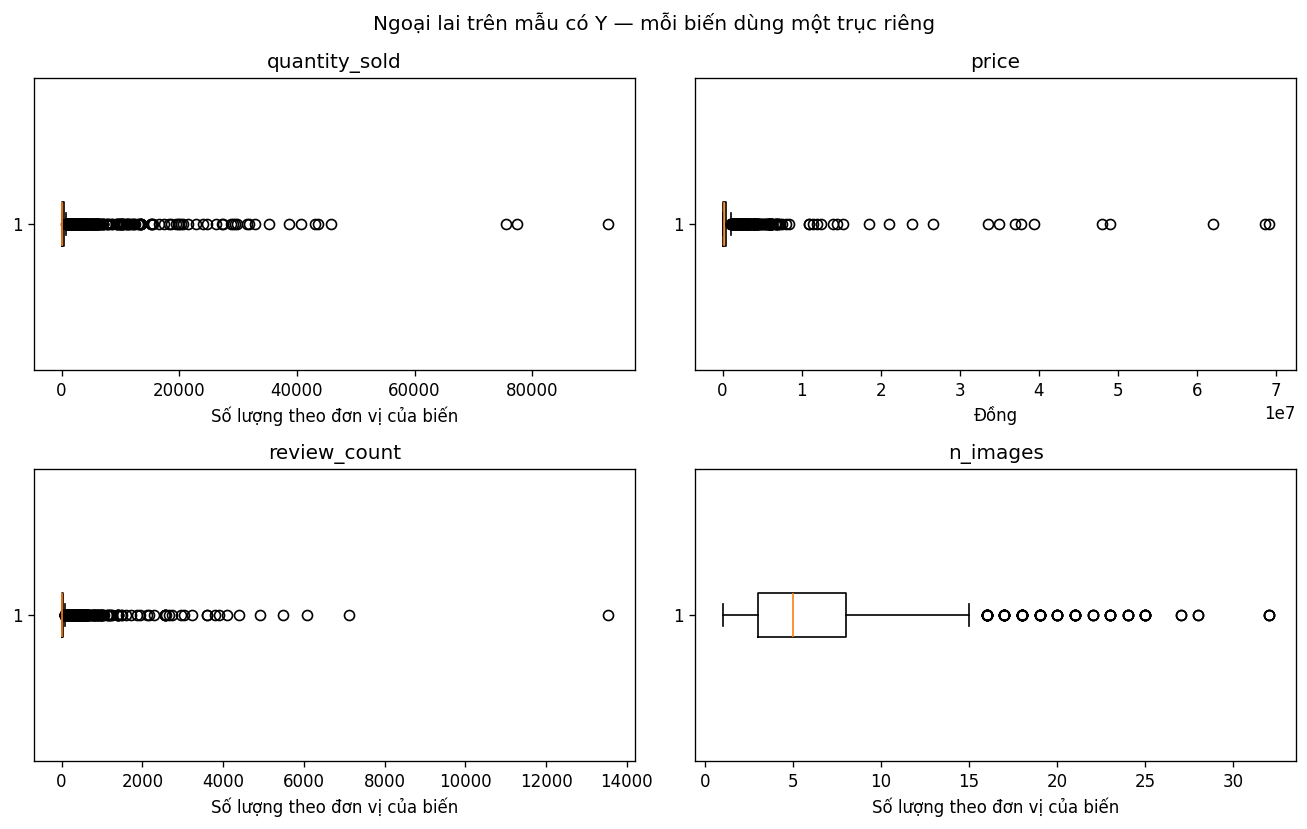

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.flat, ["quantity_sold", "price", "review_count", "n_images"]):
    ax.boxplot(df[col].dropna(), vert=False)
    ax.set_title(col)
    ax.set_xlabel("Đồng" if col == "price" else "Số lượng theo đơn vị của biến")
fig.suptitle("Ngoại lai trên mẫu có Y — mỗi biến dùng một trục riêng")
plt.tight_layout()
plt.show()
plt.close()


## 5. Bảng dữ liệu sau xử lý
### 5.1. Đối chiếu số dòng

Loại dòng thiếu Y trước, sau đó loại sản phẩm thuộc nhóm nhà bán đã chọn ở mục 3.2.3. Những giá trị X còn thiếu được giữ.


In [ ]:
print("Sản phẩm nguồn:", len(before))
print("Dòng loại vì thiếu Y:", n_missing_y)
print("Sản phẩm có Y loại tiếp theo nhà bán:", n_excluded_seller_products)
print("Sản phẩm giữ lại:", len(df))
print("Người bán giữ lại:", df["seller_id"].nunique())
print("Y còn thiếu:", int(df["quantity_sold"].isna().sum()))


Sản phẩm nguồn: 3162
Dòng loại vì thiếu Y: 1121
Sản phẩm có Y loại tiếp theo nhà bán: 7
Sản phẩm giữ lại: 2034
Người bán giữ lại: 319
Y còn thiếu: 0


### 5.2. Bảng chất lượng dữ liệu sau xử lý

In [ ]:
research_columns = [
    "product_id", "seller_id", "name", "main_category",
    "in_velocity", "is_tiki_trading", "is_branded",
    "quantity_sold", "sold_log", "sold_per_day",
    "price", "log_price_ratio", "rating_average", "review_count",
    "n_images", "has_video", "n_specs", "desc_len",
    "s_is_official", "s_avg_rating_point", "s_total_follower",
]
df_research = df[research_columns].copy()

quality_after = pd.DataFrame({
    "Count": df_research.count(), "Unique": df_research.nunique(),
    "Null": df_research.isna().sum(), "Null_pct": df_research.isna().mean() * 100,
    "DType": df_research.dtypes.astype(str),
})
display(quality_after)
display(df_research.head())


,Count,Unique,Null,Null_pct,DType
product_id,2034,2034,0,0.00000,int64
seller_id,2034,319,0,0.00000,int64
name,2034,2030,0,0.00000,string
main_category,2034,10,0,0.00000,object
in_velocity,2034,2,0,0.00000,Int64
is_tiki_trading,2034,2,0,0.00000,Int64
is_branded,2034,2,0,0.00000,Int64
quantity_sold,2034,738,0,0.00000,float64
sold_log,2034,738,0,0.00000,float64
sold_per_day,1996,1922,38,1.86824,float64


,product_id,seller_id,name,main_category,in_velocity,is_tiki_trading,is_branded,quantity_sold,sold_log,sold_per_day,...,log_price_ratio,rating_average,review_count,n_images,has_video,n_specs,desc_len,s_is_official,s_avg_rating_point,s_total_follower
0,279411794,1,Máy tính bảng Samsung Galaxy Tab A11 4G ( 4GB/...,Điện Thoại - Máy Tính Bảng,1,1,1,110.0,4.709530,0.833333,...,0.239914,0.0,0,1,0,19,346,1,4.6759,515242
1,279411764,1,Máy Tính Bảng Samsung Galaxy Tab A11 WiFi (4GB...,Điện Thoại - Máy Tính Bảng,1,1,1,186.0,5.231109,1.409091,...,0.085525,5.0,3,2,0,20,348,1,4.6759,515242
8,279231976,1,Apple iPad Air M4 11-Inch Wi-Fi,Điện Thoại - Máy Tính Bảng,1,1,1,2.0,1.098612,0.009804,...,1.212664,5.0,3,1,0,5,2614,1,4.6759,515242
10,279077078,1,Điện thoại Oppo A5x (4GB/128GB) - Hàng chính ...,Điện Thoại - Máy Tính Bảng,1,1,1,8521.0,9.050406,31.794776,...,-0.159134,0.0,0,8,0,6,4478,1,4.6759,515242
15,278890829,1,"Điện Thoại Samsung Galaxy A17 5G, Camera 50MP ...",Điện Thoại - Máy Tính Bảng,1,1,1,5113.0,8.539737,16.180380,...,0.239914,5.0,12,8,0,6,350,1,4.6759,515242


### 5.3. Đối chiếu Y gốc và log Y

Chỉ so sánh `quantity_sold` với `sold_log` trên cùng mẫu


In [ ]:
columns = ["quantity_sold", "sold_log", "price", "log_price_ratio"]

comparison = df_research[columns].agg(
    ["count", "min", "median", "max", "skew"]
).T

comparison.columns = [
    "Số quan sát", "Nhỏ nhất", "Trung vị", "Lớn nhất", "Độ lệch"
]

display(comparison.round(3))

,Số quan sát,Nhỏ nhất,Trung vị,Lớn nhất,Độ lệch
quantity_sold,2034.0,1.000,50.000,9.282700e+04,9.708
sold_log,2034.0,0.693,3.932,1.143900e+01,0.490
price,2034.0,3750.000,220000.000,6.903000e+07,12.247
log_price_ratio,2034.0,-4.396,-0.253,5.307000e+00,0.583


### 5.4. Phân phối các biến mục tiêu và giá

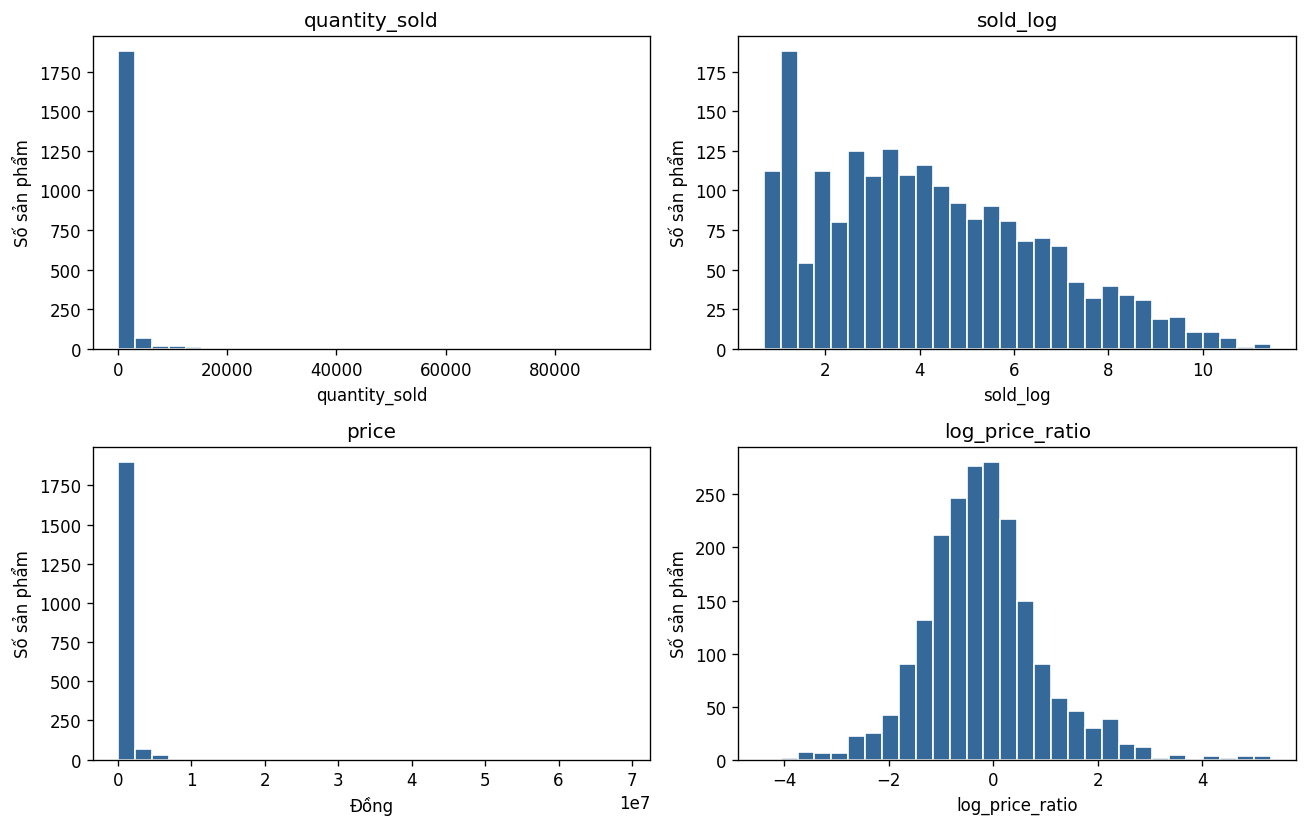

In [ ]:
# Vẽ phân phối bốn biến riêng biệt.
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.flat, ["quantity_sold", "sold_log", "price", "log_price_ratio"]):
    ax.hist(df_research[col].dropna(), bins=30, color="#34699a", edgecolor="white")
    ax.set_title(col)
    ax.set_xlabel("Đồng" if col == "price" else col)
    ax.set_ylabel("Số sản phẩm")
plt.tight_layout()
plt.show()
plt.close()


## 6. Xuất bảng 21 cột


In [ ]:
df_research.to_excel(
    excel_file, sheet_name="Du_lieu_nghien_cuu", index=False
)

print("Đã xuất:", excel_file.resolve())
print("Kích thước:", df_research.shape)

Đã xuất: C:\Users\pc\Documents\Codex\2026-10-21\files-mentioned-by-the-user-n\outputs\tiki_ten_goc_ban_tren_ngay\tiki_du_lieu_ten_goc_ban_tren_ngay.xlsx
Kích thước: (2034, 21)
